# 3-fish recording: relative amplitudes between fish with a known gain, current ∝ $(L_f/L_0)^e$

My model with the BEM conductivities (interior 100 × water, skin 0.05 × water over 0.005 cm), sink at the tail tip, sign fixed:
$m_{f,i} = -u_{f,i}$, with $u_{f,i}$ the cached unit-current voltages of fish $f$ on the 10 pairs for EOD $i$; $r_i$ the recorded
peak pattern (volts).

**Gain, chosen knowing that fish 0 emits** (an unbiased gain is assumed to exist; here it is taken from the ground truth):
$g_i = r_i\cdot m_{0,i}/\lVert m_{0,i}\rVert^2$ is fish 0's least-squares gain on EOD $i$, and one gain for all EODs,
$g = \mathrm{median}_i\, g_i$ over the EODs of the better list of good frames (`good_frames_better_list.csv`).

**Length**: with $I_f = g_0 L_f^{e}$, the prediction is $\hat v_f = g_0 L_f^e m_f = g\,\rho_f\,m_f$, where $g = g_0L_0^e$ is the gain
fitted on fish 0 and $\rho_f = (L_f/L_0)^e$. Fish 0's length enters once (inside $g$); $\rho_0 = 1$ for every e. Lengths from
`results/eod_ground_truth_3fish/fish_lengths_3fish.json` (`EOD_length_scaling_3fish.ipynb`).

**Rules** (smallest $d_f$ wins; $\hat x = x/\max|x|$):
- **A. voltage difference**: $d_f = \lVert r - g\,\rho_f\,m_f\rVert$;
- **B. shape + log amplitude**: $d_f^2 = \lVert\hat r-\hat m_f\rVert^2/\tau^2 + (\log a_f - \log(g\rho_f))^2/\sigma^2$, with
  $a_f = r\cdot m_f/\lVert m_f\rVert^2$ fish $f$'s own least-squares gain ($a_f\le 0$, a fit of the wrong sign, rules the fish
  out); $\sigma$ = standard deviation of $\log g_i$ and $\tau^2$ = median of $\lVert\hat r-\hat m_0\rVert^2$, both on fish 0 over the
  better list.

e ∈ {0, 0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10}. EODs where a fish has no model (no mask or midline) leave that fish out; if fish 0 has none the EOD counts
as wrong. For reference (not recomputed): shape only, 86.55% of all EODs, 94.50% of the better list.

Fish 0 is the smallest fish, so any e > 0 makes the silent fish's predictions larger: accuracy rising with e here does not show
which e is right (fish 0's own prediction does not depend on e).

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

RES = 'results/eod_ground_truth_3fish'
OUT = f'{RES}/conductivities'
FISH, EMITTER = (0, 1, 2), 0
EXPONENTS = [0, 0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10]

A = pd.read_csv(f'{OUT}/eod_assignments.csv', index_col='row')
cache = pd.read_pickle(f'{OUT}/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl')
assert (cache.frame.to_numpy() == A.Frame.to_numpy()).all()
R = np.stack(cache.v_rec.map(np.asarray))                                  # (n, 10) recorded peak pattern, volts
M = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))           # (n, 3, 10) unit-current model, sign fixed
ok = np.isfinite(M).all(axis=2)                                            # (n, 3) fish has a model
better = A.Frame.isin(pd.read_csv(f'{RES}/good_frames_better_list.csv').frame).to_numpy()
assert better.sum() == 6751 and len(A) == 19796
SETS = {'all EODs': np.ones(len(A), bool), 'better list of good frames': better}
L = np.array([json.load(open(f'{RES}/fish_lengths_3fish.json'))['fish'][str(f)]['L_tank'] for f in FISH])
print('L (tank units):', L.round(4), '| L_f / L_0:', (L / L[0]).round(3))

L (tank units): [0.1984 0.2761 0.2343] | L_f / L_0: [1.    1.391 1.181]


## Gain, σ and τ from fish 0 on the better list

In [2]:
def unit_max(x): return x / np.abs(x).max(axis=-1, keepdims=True)

a = (R[:, None] * M).sum(2) / (M * M).sum(2)                               # (n, 3) each fish's own least-squares gain
cal = better & ok[:, EMITTER]
g_i = a[cal, EMITTER]
g = np.median(g_i)
sigma = np.std(np.log(g_i[g_i > 0]))
tau2 = np.median((np.linalg.norm(unit_max(R) - unit_max(M[:, EMITTER]), axis=1) ** 2)[cal])
params = pd.Series({'g (median, volts per model unit)': g, 'g IQR low': np.percentile(g_i, 25), 'g IQR high': np.percentile(g_i, 75),
                    'sigma (std of log g_i)': sigma, 'tau^2 (median shape residual^2)': tau2, 'n EODs': cal.sum(),
                    'g_i <= 0 (left out of sigma)': (g_i <= 0).sum()})
params.to_csv(f'{OUT}/length_scaling_oracle_g_params.csv', header=['value'])
display(params.round(4))

g (median, volts per model unit)       0.9152
g IQR low                              0.7821
g IQR high                             1.0713
sigma (std of log g_i)                 0.3561
tau^2 (median shape residual^2)        0.3131
n EODs                              6751.0000
g_i <= 0 (left out of sigma)          57.0000
dtype: float64

## Assignments

In [3]:
def pick(d):
    d = np.where(ok, d, np.inf)
    return np.where(np.isfinite(d.min(axis=1)), d.argmin(axis=1), -1)     # -1: no fish could be compared

shape2 = np.linalg.norm(unit_max(R)[:, None] - unit_max(M), axis=2) ** 2   # (n, 3), does not depend on e
with np.errstate(invalid='ignore', divide='ignore'):
    loga = np.where(a > 0, np.log(a), np.nan)

def wilson(k, n, z=1.96):
    p = k / n; c = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n); hw = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return 100 * (c - hw), 100 * (c + hw)

rows, picks = [], {}
for e in EXPONENTS:
    rho = (L / L[EMITTER]) ** e                                            # rho_0 = 1
    pred = g * rho[None, :, None] * M
    picks[('A. voltage difference', e)] = pick(np.linalg.norm(R[:, None] - pred, axis=2))
    amp2 = (loga - np.log(g * rho)[None]) ** 2
    picks[('B. shape + log amplitude', e)] = pick(np.where(np.isfinite(amp2), shape2 / tau2 + amp2 / sigma ** 2, np.inf))
for (rule, e), p in picks.items():
    for s, m in SETS.items():
        n = int(m.sum()); k = int((p[m] == EMITTER).sum()); lo, hi = wilson(k, n)
        rows.append({'rule': rule, 'e': e, 'EODs': s, 'n EODs': n, '% fish 0 (correct)': 100 * k / n, '95% CI low': lo, '95% CI high': hi,
                     '% fish 1': 100 * (p[m] == 1).mean(), '% fish 2': 100 * (p[m] == 2).mean(), '% no pick': 100 * (p[m] == -1).mean()})
T = pd.DataFrame(rows)
assert np.allclose(T[['% fish 0 (correct)', '% fish 1', '% fish 2', '% no pick']].sum(1), 100)
T.to_csv(f'{OUT}/length_scaling_oracle_g.csv', index=False)
display(T.pivot_table(index=['rule', 'e'], columns='EODs', values='% fish 0 (correct)').round(2))

EODs                           all EODs  better list of good frames
rule                     e                                         
A. voltage difference    0.0      88.56                       97.36
                         0.5      89.62                       97.75
                         1.0      90.54                       97.88
                         1.5      91.54                       98.16
                         2.0      92.50                       98.53
                         2.5      93.51                       98.87
                         3.0      94.54                       99.21
                         4.0      95.88                       99.53
                         5.0      96.78                       99.72
                         6.0      97.69                       99.81
                         8.0      98.75                       99.94
                         10.0     99.37                       99.99
B. shape + log amplitude 0.0      85.97                       96.33
                         0.5      86.29                       96.64
                         1.0      86.60                       96.83
                         1.5      86.72                       96.92
                         2.0      87.02                       97.13
                         2.5      87.37                       97.35
                         3.0      87.63                       97.64
                         4.0      88.29                       98.15
                         5.0      88.90                       98.44
                         6.0      89.41                       98.68
                         8.0      89.94                       98.90
                         10.0     90.32                       99.04

## % correct against the exponent

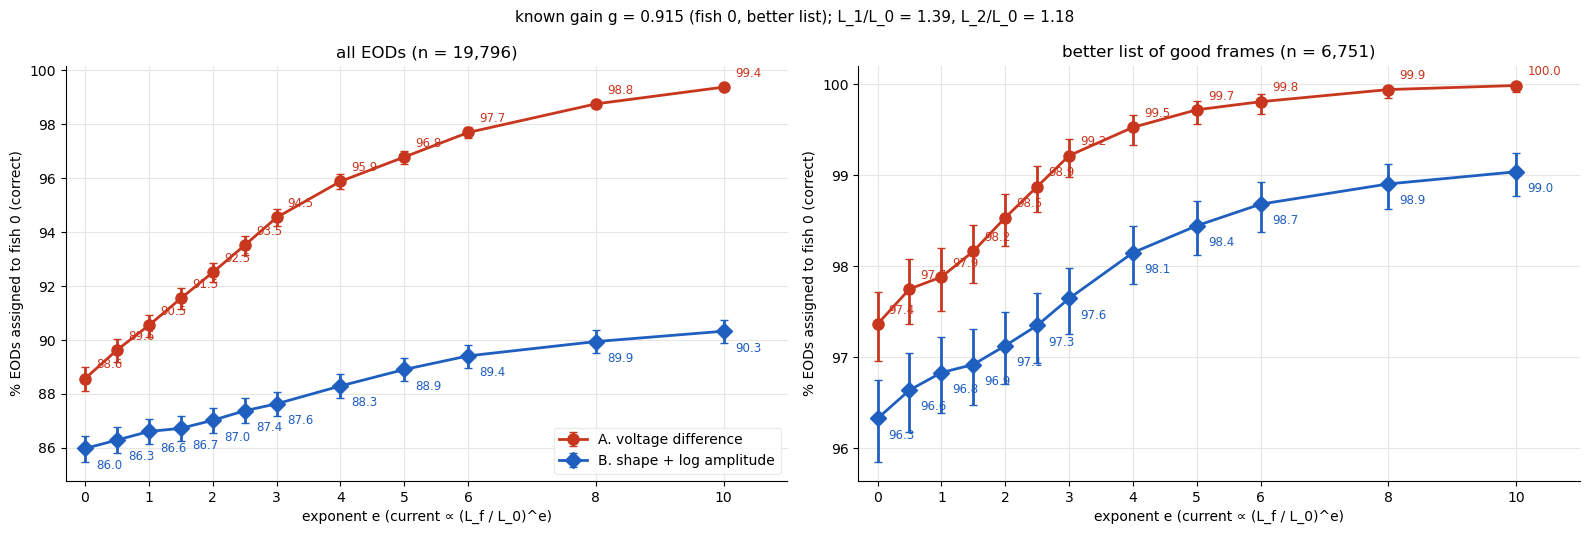

,,% fish 0 (correct),% fish 1,% fish 2,% no pick
rule,e,,,,
A. voltage difference,0.0,97.36,0.41,2.22,0.00
B. shape + log amplitude,0.0,96.33,0.77,2.65,0.25
A. voltage difference,0.5,97.75,0.39,1.87,0.00
B. shape + log amplitude,0.5,96.64,0.65,2.46,0.25
A. voltage difference,1.0,97.88,0.33,1.79,0.00
B. shape + log amplitude,1.0,96.83,0.62,2.30,0.25
A. voltage difference,1.5,98.16,0.27,1.57,0.00
B. shape + log amplitude,1.5,96.92,0.70,2.13,0.25
A. voltage difference,2.0,98.53,0.25,1.21,0.00


In [4]:
COL = {'A. voltage difference': ('#C8361E', 'o'), 'B. shape + log amplitude': ('#1F5FBF', 'D')}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3'})
fig, axs = plt.subplots(1, 2, figsize=(16, 5.4))
for ax, s in zip(axs, SETS):
    for rule, (c, mk) in COL.items():
        t = T[(T.rule == rule) & (T.EODs == s)]
        ax.errorbar(t.e, t['% fish 0 (correct)'], yerr=[t['% fish 0 (correct)'] - t['95% CI low'], t['95% CI high'] - t['% fish 0 (correct)']],
                    color=c, marker=mk, ms=8, mfc=c, lw=2, capsize=3, label=rule)
        for x, y in zip(t.e, t['% fish 0 (correct)']): ax.annotate(f'{y:.1f}', (x, y), xytext=(8, 10 if rule.startswith('A') else -12), textcoords='offset points', ha='left', va='center', fontsize=8.5, color=c)
    ax.set(title=f'{s} (n = {SETS[s].sum():,})', xlabel='exponent e (current ∝ (L_f / L_0)^e)', xticks=[0, 1, 2, 3, 4, 5, 6, 8, 10],
           ylabel='% EODs assigned to fish 0 (correct)', xlim=(-0.3, 11))
axs[0].legend(loc='lower right', frameon=True, facecolor='white', edgecolor='#e6e6e3')
fig.suptitle(f'known gain g = {g:.3f} (fish 0, better list); L_1/L_0 = {L[1] / L[0]:.2f}, L_2/L_0 = {L[2] / L[0]:.2f}', fontsize=11)
plt.tight_layout(); fig.savefig(f'{OUT}/figures/length_scaling_oracle_g.png', dpi=120); plt.show()
display(T[T.EODs == 'better list of good frames'].set_index(['rule', 'e'])[['% fish 0 (correct)', '% fish 1', '% fish 2', '% no pick']].round(2))